In [2]:
!pip install matplotlib seaborn

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from google.colab import files
uploaded = files.upload()

Saving STP-20261119131011540.csv to STP-20261119131011540.csv


In [9]:
df_salario = pd.read_csv('STP-20261119131011540.csv', sep=';', decimal=',', encoding='latin1')
print("--- Salário Mínimo ---")
display(df_salario.head())

--- Salário Mínimo ---


,Data,1619 - Salário mínimo - u.m.c.
0,01/2016,"880,00"
1,02/2016,"880,00"
2,03/2016,"880,00"
3,04/2016,"880,00"
4,05/2016,"880,00"


In [11]:
from google.colab import files
uploaded = files.upload()

Saving tabela1737.xlsx to tabela1737.xlsx


In [12]:
df_ipca = pd.read_excel('tabela1737.xlsx')

print("--- IPCA / Inflação ---")
display(df_ipca.head(10))

--- IPCA / Inflação ---


,"Tabela 1737 - IPCA - Série histórica com número-índice, variação mensal e variações acumuladas em 3 meses, em 6 meses, no ano e em 12 meses (a partir de dezembro/1979)",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 121,Unnamed: 122,Unnamed: 123,Unnamed: 124,Unnamed: 125,Unnamed: 126,Unnamed: 127,Unnamed: 128,Unnamed: 129,Unnamed: 130
0,Variável - IPCA - Número-índice (base: dezembr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Mês,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,janeiro 2016,fevereiro 2016,março 2016,abril 2016,maio 2016,junho 2016,julho 2016,agosto 2016,setembro 2016,...,janeiro 2026,fevereiro 2026,março 2026,abril 2026,maio 2026,junho 2026,julho 2026,agosto 2026,setembro 2026,outubro 2026
3,Brasil,4550.23,4591.18,4610.92,4639.05,4675.23,4691.59,4715.99,4736.74,4740.53,...,7427.72,7479.71,7545.53,7596.09,7640.15,7652.37,7657.73,7633.23,7695.82,7706.59
4,Fonte: IBGE - Índice Nacional de Preços ao Con...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df_ipca = pd.read_excel('tabela1737.xlsx', header=3)

print("--- IPCA Limpo ---")
display(df_ipca.head())

--- IPCA Limpo ---


,Unnamed: 0,janeiro 2016,fevereiro 2016,março 2016,abril 2016,maio 2016,junho 2016,julho 2016,agosto 2016,setembro 2016,...,janeiro 2026,fevereiro 2026,março 2026,abril 2026,maio 2026,junho 2026,julho 2026,agosto 2026,setembro 2026,outubro 2026
0,Brasil,4550.23,4591.18,4610.92,4639.05,4675.23,4691.59,4715.99,4736.74,4740.53,...,7427.72,7479.71,7545.53,7596.09,7640.15,7652.37,7657.73,7633.23,7695.82,7706.59
1,Fonte: IBGE - Índice Nacional de Preços ao Con...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
df_ipca_brasil = df_ipca.iloc[[0]].copy()

df_ipca_brasil = df_ipca_brasil.drop(columns=['Unnamed: 0'])

df_ipca_melted = pd.melt(df_ipca_brasil, var_name='Mes_Ano', value_name='IPCA_Indice')

print("--- IPCA Transformado (Linhas por Mês) ---")
display(df_ipca_melted.head(10))

--- IPCA Transformado (Linhas por Mês) ---


,Mes_Ano,IPCA_Indice
0,janeiro 2016,4550.23
1,fevereiro 2016,4591.18
2,março 2016,4610.92
3,abril 2016,4639.05
4,maio 2016,4675.23
5,junho 2016,4691.59
6,julho 2016,4715.99
7,agosto 2016,4736.74
8,setembro 2016,4740.53
9,outubro 2016,4752.86


In [15]:
df_salario['Data_Limpa'] = pd.to_datetime(df_salario['Data'], format='%d/%m/%Y', errors='coerce')
df_salario['AnoMes'] = df_salario['Data_Limpa'].dt.to_period('M')

meses_pt = {
    'janeiro': '01', 'fevereiro': '02', 'março': '03', 'abril': '04',
    'maio': '05', 'junho': '06', 'julho': '07', 'agosto': '08',
    'setembro': '09', 'outubro': '10', 'novembro': '11', 'dezembro': '12'
}

def converte_mes_ano(texto):
    for mes_pt, num in meses_pt.items():
        if mes_pt in str(texto).lower():
            ano = ''.join(filter(str.isdigit, str(texto)))
            return f"{ano}-{num}-01"
    return None

df_ipca_melted['Data_Limpa'] = pd.to_datetime(df_ipca_melted['Mes_Ano'].apply(converte_mes_ano), errors='coerce')
df_ipca_melted['AnoMes'] = df_ipca_melted['Data_Limpa'].dt.to_period('M')

df_final = pd.merge(df_salario, df_ipca_melted, on='AnoMes', how='inner')

print("--- Tabela Unida (Salário Mínimo + IPCA) ---")
display(df_final.head())

--- Tabela Unida (Salário Mínimo + IPCA) ---


,Data,1619 - Salário mínimo - u.m.c.,Data_Limpa_x,AnoMes,Mes_Ano,IPCA_Indice,Data_Limpa_y


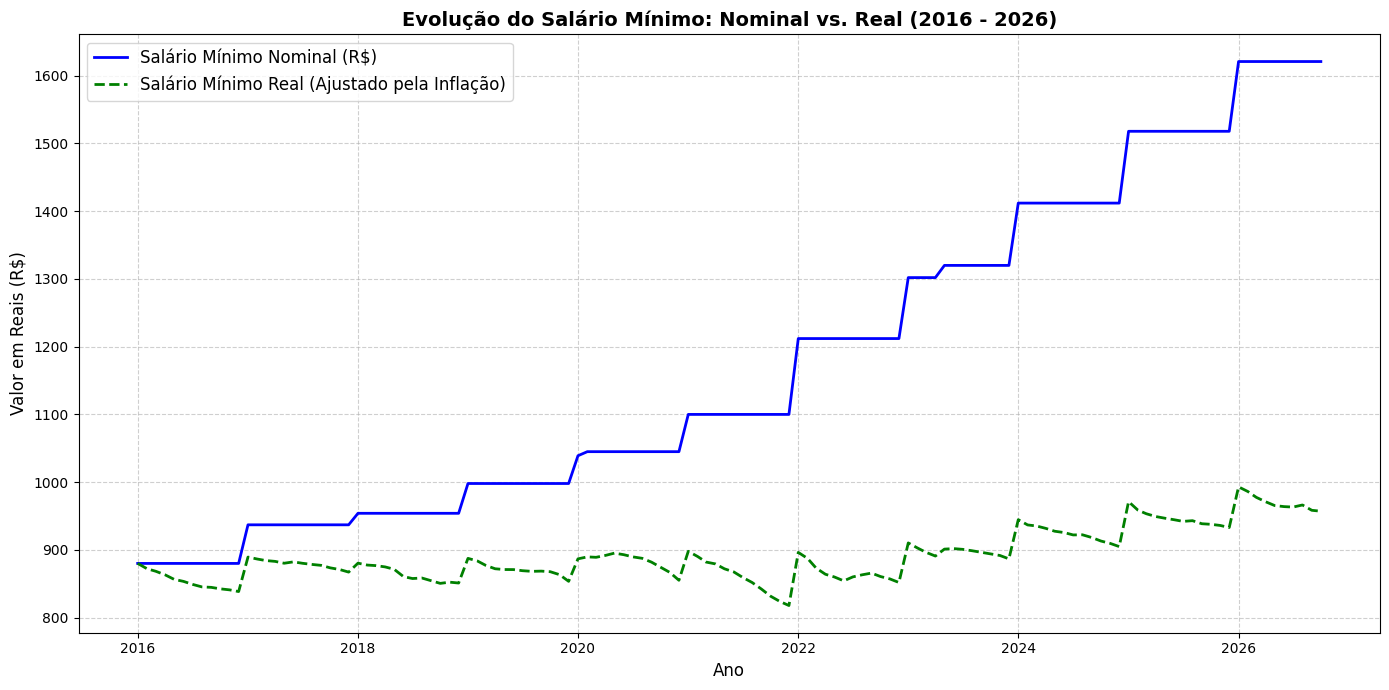

In [20]:
df_final['Salario_Num'] = (
    df_final['1619 - Salário mínimo - u.m.c.']
    .astype(str)
    .str.replace('.', '', regex=False)  # Remove o ponto de milhar (ex: 1.039 vira 1039)
    .str.replace(',', '.', regex=False) # Troca a vírgula decimal por ponto
    .astype(float)
)

df_final['IPCA_Num'] = pd.to_numeric(df_final['IPCA_Indice'], errors='coerce')

indice_base = df_final['IPCA_Num'].iloc[0]
df_final['Salario_Real'] = (df_final['Salario_Num'] / df_final['IPCA_Num']) * indice_base

plt.figure(figsize=(14, 7))
plt.plot(df_final['Data_Limpa_x'], df_final['Salario_Num'], label='Salário Mínimo Nominal (R$)', color='blue', linewidth=2)
plt.plot(df_final['Data_Limpa_x'], df_final['Salario_Real'], label='Salário Mínimo Real (Ajustado pela Inflação)', color='green', linewidth=2, linestyle='--')

plt.title('Evolução do Salário Mínimo: Nominal vs. Real (2016 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Valor em Reais (R$)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.savefig('evolucao_salario_minimo_real.png', dpi=300, bbox_inches='tight')

plt.show()
